# Ejercicio 2 - Prueba Chi Cuadrado aplicada a Customer Churn

En este ejercicio vamos a analizar el dataset `telecom-customer-churn.tab`.

El objetivo es determinar qué variables categóricas del dataset están relacionadas con la variable `churn`.

La variable `churn` indica si un cliente abandonó o no la empresa de telecomunicaciones.

Desde el punto de vista de Marketing, este análisis sirve para reconocer qué características de los clientes pueden estar asociadas con la pérdida de clientes.

Para eso vamos a usar la **Prueba Chi Cuadrado de Independencia**.


## ¿Qué queremos comprobar?

Queremos saber si existe relación entre cada variable categórica y `churn`.

Por ejemplo:

- ¿El tipo de contrato está relacionado con la pérdida de clientes?
- ¿El método de pago está relacionado con churn?
- ¿Tener servicio de internet influye en la pérdida de clientes?
- ¿El soporte técnico está relacionado con churn?

Para cada variable vamos a plantear dos hipótesis:

### Hipótesis nula

H0: la variable analizada y `churn` son independientes.

Esto significa que no hay relación entre ambas variables.

### Hipótesis alternativa

H1: la variable analizada y `churn` no son independientes.

Esto significa que sí hay relación entre ambas variables.

## Nivel de significancia

Vamos a trabajar con:


- `alpha = 0.05`


Esto significa que usaremos un nivel de significancia del 5%.

La regla de decisión será:

- Si `p_value < 0.05`, rechazamos H0.
- Si `p_value >= 0.05`, no rechazamos H0.

Por lo tanto:

- Si `p_value < 0.05`, concluimos que la variable sí está relacionada con `churn`.
- Si `p_value >= 0.05`, concluimos que no hay evidencia suficiente para afirmar que la variable está relacionada con `churn`.

In [ ]:
# ==========================================================
# CELDA 1 - Importamos las librerías necesarias
# ==========================================================

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

from scipy.stats import chi2_contingency

pd.set_option("display.max_columns", None)
pd.set_option("display.max_rows", 200)

In [ ]:
# ==========================================================
# CELDA 3 - Leemos el dataset
# ==========================================================

df = pd.read_csv("/content/telecom-customer-churn.tab", sep="\t")

print("Cantidad de filas y columnas:", df.shape)

df.head()

Cantidad de filas y columnas: (7043, 21)


,gender,SeniorCitizen,Partner,Dependents,tenure,PhoneService,MultipleLines,InternetService,OnlineSecurity,OnlineBackup,DeviceProtection,TechSupport,StreamingTV,StreamingMovies,Contract,PaperlessBilling,PaymentMethod,MonthlyCharges,TotalCharges,Churn,customerID
0,Female,0,Yes,No,1.0,No,No phone service,DSL,No,Yes,No,No,No,No,Month-to-month,Yes,Electronic check,29.85,29.85,No,7590-VHVEG
1,Male,0,No,No,34.0,Yes,No,DSL,Yes,No,Yes,No,No,No,One year,No,Mailed check,56.95,1889.50,No,5575-GNVDE
2,Male,0,No,No,2.0,Yes,No,DSL,Yes,Yes,No,No,No,No,Month-to-month,Yes,Mailed check,53.85,108.15,Yes,3668-QPYBK
3,Male,0,No,No,45.0,No,No phone service,DSL,Yes,No,Yes,Yes,No,No,One year,No,Bank transfer (automatic),42.30,1840.75,No,7795-CFOCW
4,Female,0,No,No,2.0,Yes,No,Fiber optic,No,No,No,No,No,No,Month-to-month,Yes,Electronic check,70.70,151.65,Yes,9237-HQITU


In [ ]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 7043 entries, 0 to 7042
Data columns (total 21 columns):
 #   Column            Non-Null Count  Dtype  
---  ------            --------------  -----  
 0   gender            7043 non-null   object 
 1   SeniorCitizen     7043 non-null   int64  
 2   Partner           7043 non-null   object 
 3   Dependents        7043 non-null   object 
 4   tenure            7043 non-null   float64
 5   PhoneService      7043 non-null   object 
 6   MultipleLines     7043 non-null   object 
 7   InternetService   7043 non-null   object 
 8   OnlineSecurity    7043 non-null   object 
 9   OnlineBackup      7043 non-null   object 
 10  DeviceProtection  7043 non-null   object 
 11  TechSupport       7043 non-null   object 
 12  StreamingTV       7043 non-null   object 
 13  StreamingMovies   7043 non-null   object 
 14  Contract          7043 non-null   object 
 15  PaperlessBilling  7043 non-null   object 
 16  PaymentMethod     7043 non-null   object 


Observamos cuántos clientes pertenecen a cada categoría de `churn`.

La variable `churn` es nuestra variable objetivo.

Generalmente indica:

- `Yes`: el cliente abandonó la empresa.
- `No`: el cliente no abandonó la empresa.


In [ ]:
df["Churn"].value_counts()

,count
Churn,
No,5174
Yes,1869


In [ ]:
variables_categoricas = df.select_dtypes(include="object").columns.tolist()

variables_categoricas

['gender',
 'Partner',
 'Dependents',
 'PhoneService',
 'MultipleLines',
 'InternetService',
 'OnlineSecurity',
 'OnlineBackup',
 'DeviceProtection',
 'TechSupport',
 'StreamingTV',
 'StreamingMovies',
 'Contract',
 'PaperlessBilling',
 'PaymentMethod',
 'Churn',
 'customerID']

In [ ]:
variables_a_analizar = [
    col for col in variables_categoricas
    if col != "Churn" and col != "SeniorCitizen"
]

variables_a_analizar

['gender',
 'Partner',
 'Dependents',
 'PhoneService',
 'MultipleLines',
 'InternetService',
 'OnlineSecurity',
 'OnlineBackup',
 'DeviceProtection',
 'TechSupport',
 'StreamingTV',
 'StreamingMovies',
 'Contract',
 'PaperlessBilling',
 'PaymentMethod',
 'customerID']

## ¿Qué hacemos en esta celda?

Armamos una lista con las variables categóricas que vamos a analizar.

Quitamos `churn` porque no queremos compararla consigo misma.

También quitamos `SeniorCitizen` porque la consigna indica que no debemos usar esa columna.

Entonces, cada una de las variables restantes será comparada con `churn` mediante la Prueba Chi Cuadrado.

In [ ]:
# Funcion ChiSquare
def prueba_chi_cuadrado(variable):

    # Armamos la tabla de contingencia
    tabla = pd.crosstab(df[variable], df["Churn"])

    # Aplicamos la prueba chi cuadrado
    chi2, p, grados_libertad, esperados = chi2_contingency(tabla)

    # Guardamos los resultados en un diccionario
    resultado = {
        "Variable": variable,
        "Chi cuadrado": chi2,
        "p_value": p,
        "Grados de libertad": grados_libertad,
        "Relación con churn": "Sí" if p < 0.05 else "No"
    }

    return resultado

In [ ]:
resultados = []

for variable in variables_a_analizar:
    resultado = prueba_chi_cuadrado(variable)
    resultados.append(resultado)

df_resultados = pd.DataFrame(resultados)

df_resultados = df_resultados.sort_values("p_value")

df_resultados

,Variable,Chi cuadrado,p_value,Grados de libertad,Relación con churn
12,Contract,1184.596572,5.863038e-258,2,Sí
6,OnlineSecurity,849.998968,2.661150e-185,2,Sí
9,TechSupport,828.197068,1.443084e-180,2,Sí
5,InternetService,732.309590,9.571788e-160,2,Sí
14,PaymentMethod,648.142327,3.682355e-140,3,Sí
7,OnlineBackup,601.812790,2.079759e-131,2,Sí
8,DeviceProtection,558.419369,5.505219e-122,2,Sí
11,StreamingMovies,375.661479,2.667757e-82,2,Sí
10,StreamingTV,374.203943,5.528994e-82,2,Sí
13,PaperlessBilling,258.277649,4.073355e-58,1,Sí


In [ ]:
variables_relacionadas = df_resultados[df_resultados["Relación con churn"] == "Sí"]
variables_no_relacionadas = df_resultados[df_resultados["Relación con churn"] == "No"]

print("Variables relacionadas con churn:")
display(variables_relacionadas)

print("Variables NO relacionadas con churn:")
display(variables_no_relacionadas)

Variables relacionadas con churn:


,Variable,Chi cuadrado,p_value,Grados de libertad,Relación con churn
12,Contract,1184.596572,5.863038e-258,2,Sí
6,OnlineSecurity,849.998968,2.661150e-185,2,Sí
9,TechSupport,828.197068,1.443084e-180,2,Sí
5,InternetService,732.309590,9.571788e-160,2,Sí
14,PaymentMethod,648.142327,3.682355e-140,3,Sí
7,OnlineBackup,601.812790,2.079759e-131,2,Sí
8,DeviceProtection,558.419369,5.505219e-122,2,Sí
11,StreamingMovies,375.661479,2.667757e-82,2,Sí
10,StreamingTV,374.203943,5.528994e-82,2,Sí
13,PaperlessBilling,258.277649,4.073355e-58,1,Sí


Variables NO relacionadas con churn:


,Variable,Chi cuadrado,p_value,Grados de libertad,Relación con churn
3,PhoneService,0.915033,0.338783,1,No
0,gender,0.484083,0.486579,1,No
15,customerID,7043.000000,0.494398,7042,No


In [ ]:
lista_relacionadas = variables_relacionadas["Variable"].tolist()

lista_relacionadas

['Contract',
 'OnlineSecurity',
 'TechSupport',
 'InternetService',
 'PaymentMethod',
 'OnlineBackup',
 'DeviceProtection',
 'StreamingMovies',
 'StreamingTV',
 'PaperlessBilling',
 'Dependents',
 'Partner',
 'MultipleLines']

In [ ]:

for variable in lista_relacionadas:

    print("="*70)
    print("Variable:", variable)

    tabla = pd.crosstab(df[variable], df["Churn"])

    display(tabla)

Variable: Contract


Churn,No,Yes
Contract,,
Month-to-month,2220,1655
One year,1307,166
Two year,1647,48


Variable: OnlineSecurity


Churn,No,Yes
OnlineSecurity,,
No,2037,1461
No internet service,1413,113
Yes,1724,295


Variable: TechSupport


...

Churn,No,Yes
Dependents,,
No,3390,1543
Yes,1784,326


Variable: Partner


Churn,No,Yes
Partner,,
No,2441,1200
Yes,2733,669


Variable: MultipleLines


Churn,No,Yes
MultipleLines,,
No,2541,849
No phone service,512,170
Yes,2121,850


In [ ]:
for variable in lista_relacionadas:

    print("="*70)
    print("Variable:", variable)

    tabla_porcentaje = pd.crosstab(
        df[variable],
        df["Churn"],
        normalize="index"
    ) * 100

    display(tabla_porcentaje.round(2))

Variable: Contract


Churn,No,Yes
Contract,,
Month-to-month,57.29,42.71
One year,88.73,11.27
Two year,97.17,2.83


Variable: OnlineSecurity


Churn,No,Yes
OnlineSecurity,,
No,58.23,41.77
No internet service,92.60,7.40
Yes,85.39,14.61


Variable: TechSupport


...

Churn,No,Yes
Dependents,,
No,68.72,31.28
Yes,84.55,15.45


Variable: Partner


Churn,No,Yes
Partner,,
No,67.04,32.96
Yes,80.34,19.66


Variable: MultipleLines


Churn,No,Yes
MultipleLines,,
No,74.96,25.04
No phone service,75.07,24.93
Yes,71.39,28.61


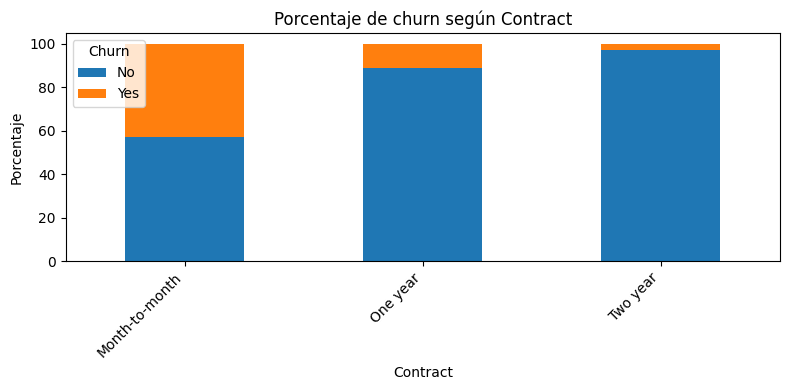

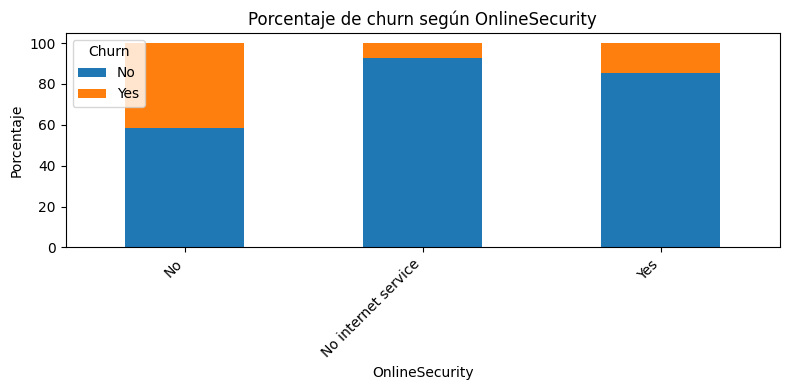

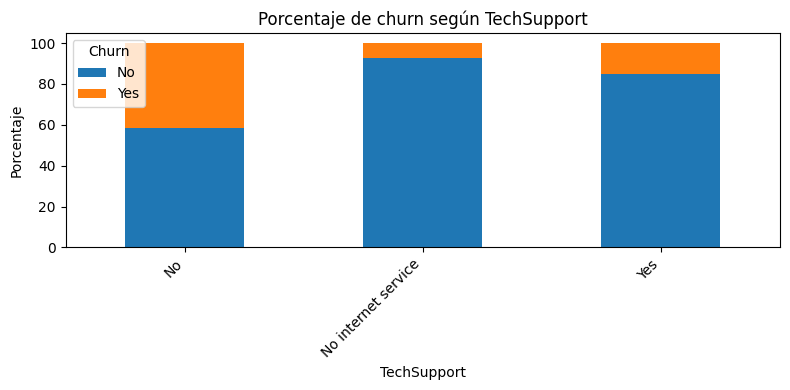

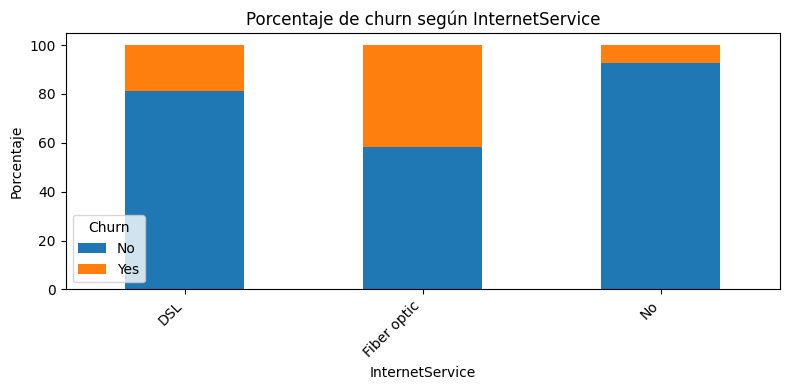

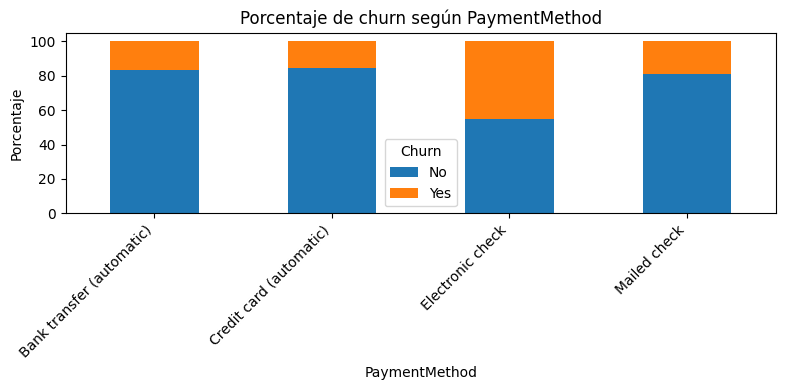

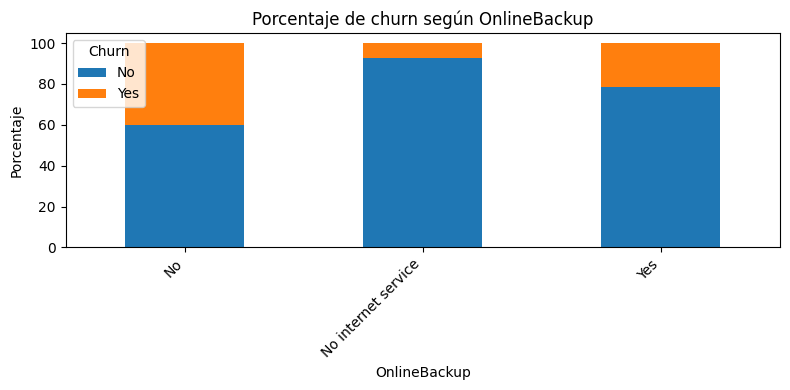

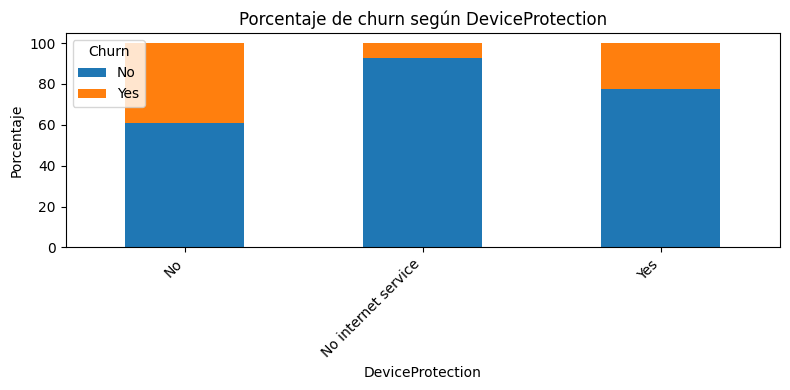

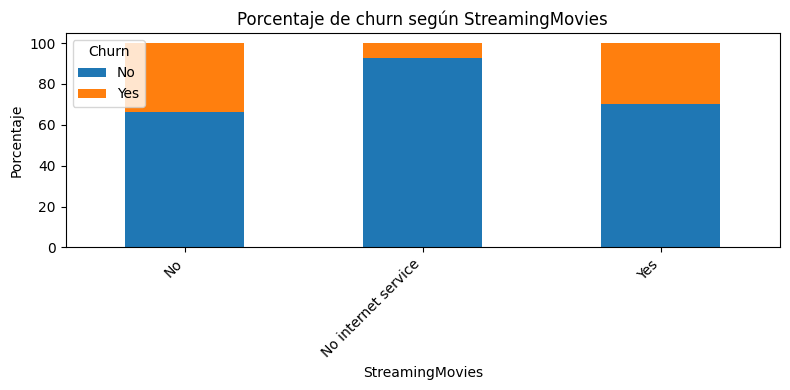

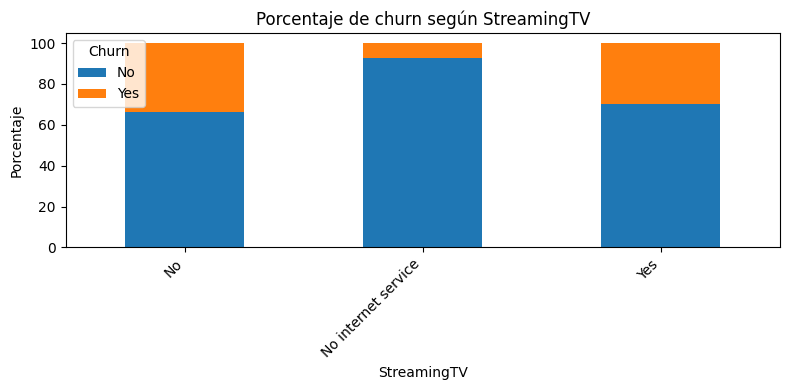

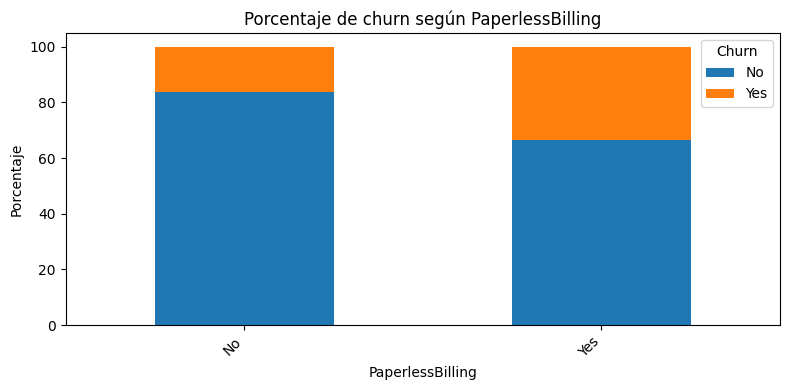

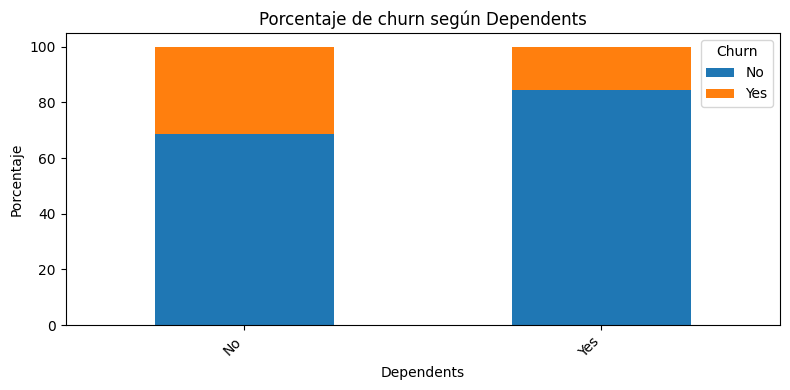

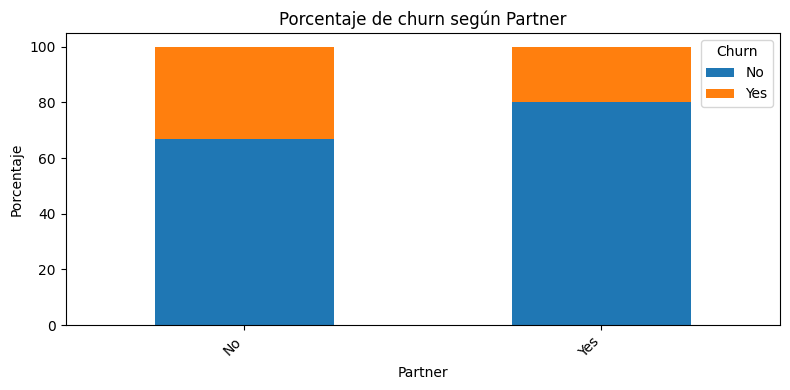

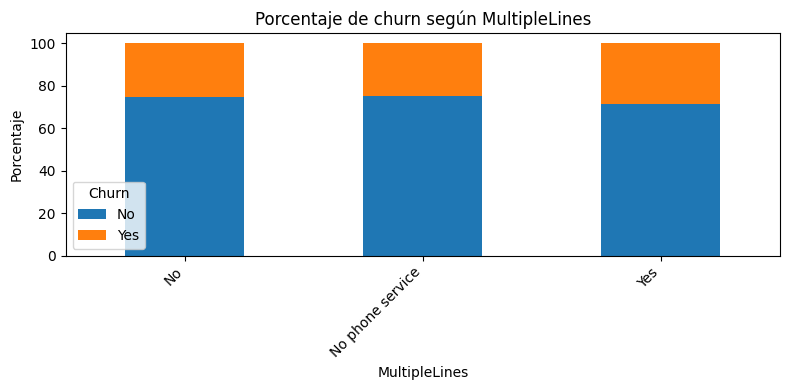

In [ ]:
for variable in lista_relacionadas:

    tabla_porcentaje = pd.crosstab(
        df[variable],
        df["Churn"],
        normalize="index"
    ) * 100

    tabla_porcentaje.plot(
        kind="bar",
        stacked=True,
        figsize=(8, 4)
    )

    plt.title(f"Porcentaje de churn según {variable}")
    plt.xlabel(variable)
    plt.ylabel("Porcentaje")
    plt.xticks(rotation=45, ha="right")
    plt.legend(title="Churn")
    plt.tight_layout()
    plt.show()

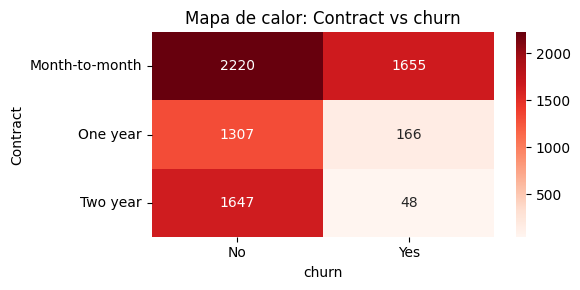

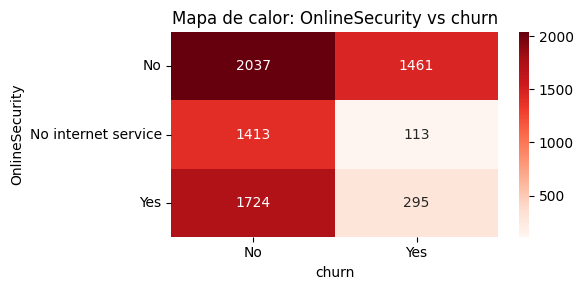

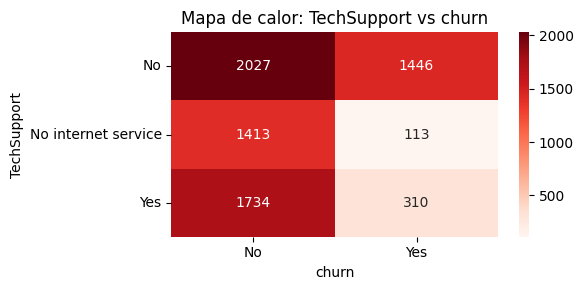

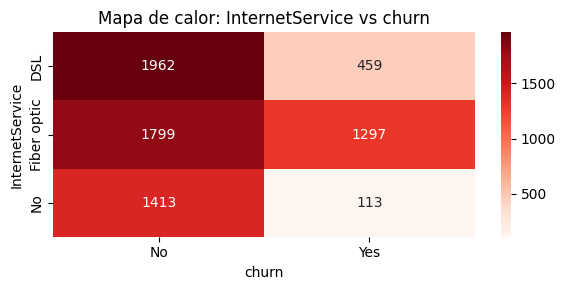

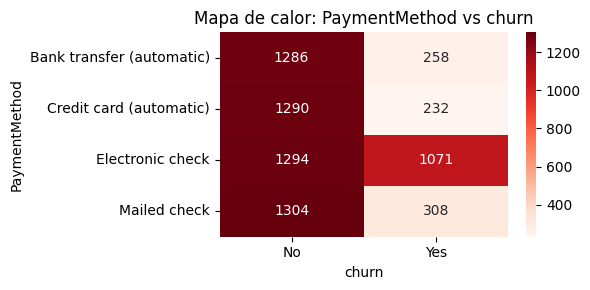

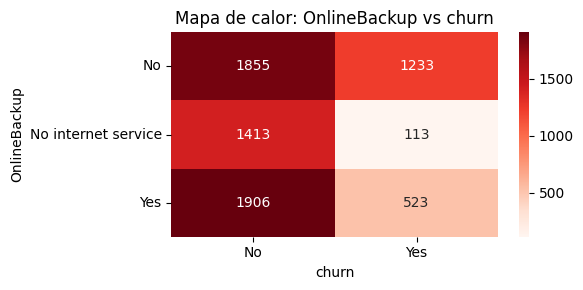

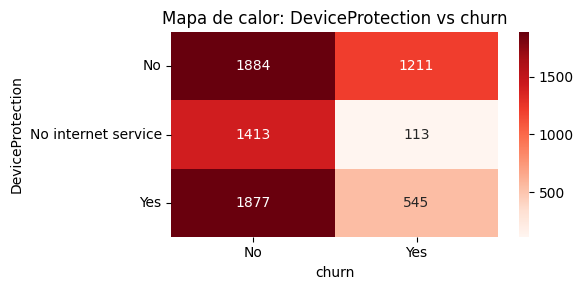

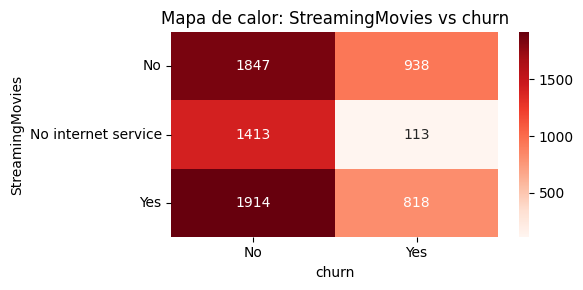

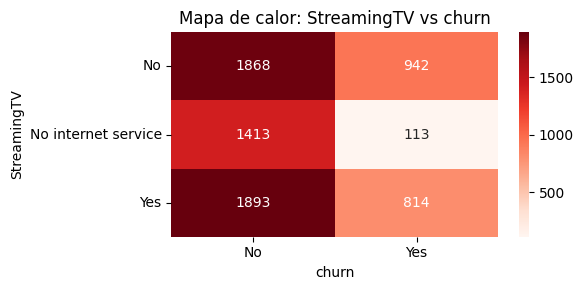

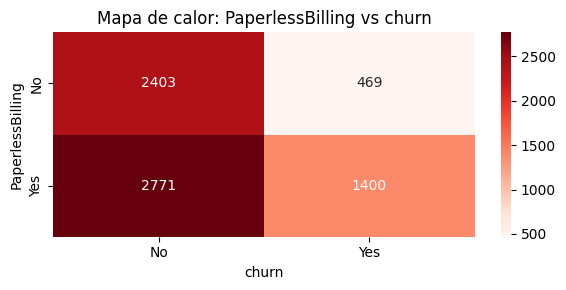

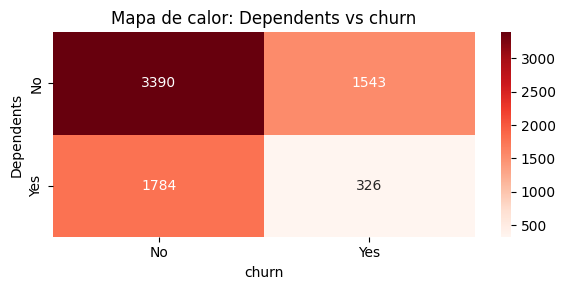

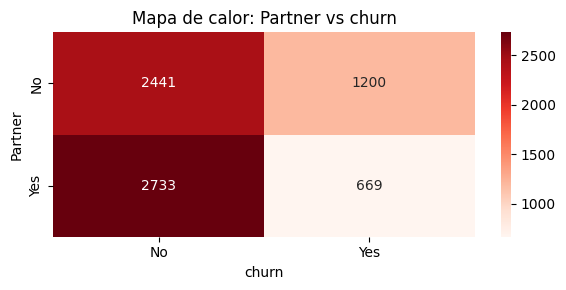

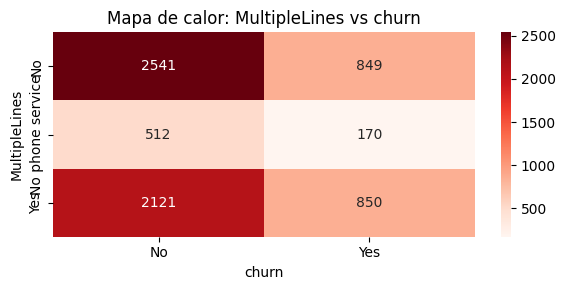

In [ ]:

for variable in lista_relacionadas:

    tabla = pd.crosstab(df[variable], df["Churn"])

    plt.figure(figsize=(6, 3))

    sns.heatmap(
        tabla,
        annot=True,
        cmap="Reds",
        fmt="g"
    )

    plt.title(f"Mapa de calor: {variable} vs churn")
    plt.xlabel("churn")
    plt.ylabel(variable)
    plt.tight_layout()
    plt.show()

In [ ]:

for _, fila in df_resultados.iterrows():

    variable = fila["Variable"]
    chi2 = fila["Chi cuadrado"]
    p = fila["p_value"]
    relacion = fila["Relación con churn"]

    if relacion == "Sí":
        print(
            f"La variable {variable} SÍ está relacionada con churn. "
            f"Chi cuadrado = {chi2:.4f}, p-value = {p:.6f}."
        )
    else:
        print(
            f"La variable {variable} NO presenta relación estadísticamente significativa con churn. "
            f"Chi cuadrado = {chi2:.4f}, p-value = {p:.6f}."
        )

La variable Contract SÍ está relacionada con churn. Chi cuadrado = 1184.5966, p-value = 0.000000.
La variable OnlineSecurity SÍ está relacionada con churn. Chi cuadrado = 849.9990, p-value = 0.000000.
La variable TechSupport SÍ está relacionada con churn. Chi cuadrado = 828.1971, p-value = 0.000000.
La variable InternetService SÍ está relacionada con churn. Chi cuadrado = 732.3096, p-value = 0.000000.
La variable PaymentMethod SÍ está relacionada con churn. Chi cuadrado = 648.1423, p-value = 0.000000.
La variable OnlineBackup SÍ está relacionada con churn. Chi cuadrado = 601.8128, p-value = 0.000000.
La variable DeviceProtection SÍ está relacionada con churn. Chi cuadrado = 558.4194, p-value = 0.000000.
La variable StreamingMovies SÍ está relacionada con churn. Chi cuadrado = 375.6615, p-value = 0.000000.
La variable StreamingTV SÍ está relacionada con churn. Chi cuadrado = 374.2039, p-value = 0.000000.
La variable PaperlessBilling SÍ está relacionada con churn. Chi cuadrado = 258.2776

In [ ]:
# ==========================================================
# CELDA - GENERAR TEXTO CON RESULTADOS PARA CONCLUSIONES
# ==========================================================

alpha = 0.05

texto_resultados = ""

texto_resultados += "RESULTADOS DE LA PRUEBA CHI CUADRADO\n"
texto_resultados += "="*60 + "\n\n"
texto_resultados += f"Nivel de significancia utilizado: alpha = {alpha}\n\n"

for _, fila in df_resultados.iterrows():

    variable = fila["Variable"]
    chi2 = fila["Chi cuadrado"]
    p = fila["p_value"]
    gl = fila["Grados de libertad"]
    relacion = fila["Relación con churn"]

    texto_resultados += f"Variable analizada: {variable}\n"
    texto_resultados += f"Chi cuadrado: {chi2:.4f}\n"
    texto_resultados += f"p-value: {p:.6f}\n"
    texto_resultados += f"Grados de libertad: {gl}\n"

    if p < alpha:
        texto_resultados += "Decisión: se rechaza H0.\n"
        texto_resultados += f"Conclusión: la variable {variable} SÍ presenta relación estadísticamente significativa con churn.\n"
    else:
        texto_resultados += "Decisión: no se rechaza H0.\n"
        texto_resultados += f"Conclusión: la variable {variable} NO presenta evidencia suficiente de relación con churn.\n"

    texto_resultados += "-"*60 + "\n\n"

print(texto_resultados)

RESULTADOS DE LA PRUEBA CHI CUADRADO

Nivel de significancia utilizado: alpha = 0.05

Variable analizada: Contract
Chi cuadrado: 1184.5966
p-value: 0.000000
Grados de libertad: 2
Decisión: se rechaza H0.
Conclusión: la variable Contract SÍ presenta relación estadísticamente significativa con churn.
------------------------------------------------------------

Variable analizada: OnlineSecurity
Chi cuadrado: 849.9990
p-value: 0.000000
Grados de libertad: 2
Decisión: se rechaza H0.
Conclusión: la variable OnlineSecurity SÍ presenta relación estadísticamente significativa con churn.
------------------------------------------------------------

Variable analizada: TechSupport
Chi cuadrado: 828.1971
p-value: 0.000000
Grados de libertad: 2
Decisión: se rechaza H0.
Conclusión: la variable TechSupport SÍ presenta relación estadísticamente significativa con churn.
------------------------------------------------------------

Variable analizada: InternetService
Chi cuadrado: 732.3096
p-value: 0.